# 🏥 Introduction to RAG Systems — Health Documents

**Retrieval-Augmented Generation (RAG)** combines two ideas:
1. **Retrieval**: Find the most relevant pieces of text from a document collection given a query.
2. **Generation**: Feed those pieces to a language model so it can answer the query with grounded context.

Without RAG, a model can only use knowledge baked in during training. With RAG, it can answer questions about *any* document you provide — even ones published yesterday.

```
User Query
    │
    ▼
[Embedding Model] ──► Query Vector
                           │
                           ▼
                  [Vector Database] ──► Top-K Chunks
                                              │
                                              ▼
                                   [LLM (Mistral 7B)] ──► Answer
```

**Estimated time:** 30 minutes  
**Runtime required:** GPU (T4 or better) — *Runtime → Change runtime type → T4 GPU*

---
### What we'll build
| Step | What happens |
|------|--------------|
| 1 | Install dependencies |
| 2 | Download health PDFs (medical research papers) |
| 3 | Parse & chunk the PDFs |
| 4 | Generate embeddings and build a vector store |
| 5 | Build the RAG chain with Mistral 7B (4-bit) |
| 6 | Ask questions and evaluate the answers |

## ⚙️ Step 1 — Install Dependencies

We install:
- **LangChain** — orchestration framework for RAG pipelines
- **FAISS** — fast vector similarity search library by Meta
- **sentence-transformers** — lightweight embedding models
- **bitsandbytes + transformers** — 4-bit quantization of Mistral 7B
- **pypdf** — PDF text extraction

> ⏱ This cell takes ~3 minutes on a fresh Colab runtime.

In [ ]:
#%%capture
!pip install langchain langchain-community langchain-huggingface langchain-text-splitters
!pip install faiss-cpu sentence-transformers
!pip install transformers accelerate bitsandbytes
!pip install pypdf requests
!pip install rouge-score bert-score
print('✅ All packages installed.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 86.5 MB/s eta 0:00:00
✅ All packages installed.


In [ ]:
!pip freeze > requirements.txt

In [ ]:
# Verify GPU is available
import torch
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('⚠️  No GPU detected. Go to Runtime → Change runtime type → T4 GPU')

CUDA available: True
GPU: Tesla T4
VRAM: 15.6 GB


## 📄 Step 2 — Download Health PDFs

We download **4 open-access medical research papers** from PubMed Central (PMC).
These are real papers on cardiovascular disease, diabetes, hypertension, and obesity —
freely available under open-access licenses.

> **Kaggle alternative:** If you prefer a Kaggle dataset, you can use
> [`rsrishav/pubmed-health-question-answering`](https://www.kaggle.com/datasets/jpmckinney/open-government-licence-collection)
> or [`neelblabla/openstax-textbooks-pdfs`](https://www.kaggle.com/datasets/neelblabla/openstax-textbooks-pdfs)
> and mount it with `kagglehub.dataset_download()`. The rest of the pipeline is identical.

In [ ]:
import os, requests
import shutil
from google.colab import drive

os.makedirs('health_pdfs', exist_ok=True)
drive.mount("/content/drive")

# Open-access PDFs from PubMed Central
papers = [
    {
        'filename': 'cardiovascular_risk.pdf',
        'path': '/content/drive/MyDrive/docs-health/futurehealth-6-2-94.pdf',
        'topic': 'Cardiovascular Risk Factors'
    },
    {
        'filename': 'type2_diabetes.pdf',
        'path': '/content/drive/MyDrive/docs-health/foods-08-00092.pdf',
        'topic': 'Type 2 Diabetes Management'
    },
    {
        'filename': 'hypertension.pdf',
        'path': '/content/drive/MyDrive/docs-health/materials-09-00620.pdf',
        'topic': 'Hypertension'
    },
    {
        'filename': 'obesity_health.pdf',
        'path': '/content/drive/MyDrive/docs-health/copd-12-2465.pdf',
        'topic': 'Obesity and Metabolic Syndrome'
    },
]

downloaded = []

for paper in papers:
    path = f"health_pdfs/{paper['filename']}"

    try:
        shutil.copy(paper['path'], path)
        downloaded.append(path)
        print(f"✅ Downloaded: {paper['topic']}")
    except Exception as e:
        print(f"⚠️  Error downloading {paper['topic']}: {e}")

# Fallback: create a small synthetic health document if downloads fail
if len(downloaded) == 0:
    print('\n⚙️  Using fallback synthetic documents...')
    from fpdf import FPDF
    !pip install fpdf2 -q
    from fpdf import FPDF
    texts = {
        'diabetes_overview.pdf': """
        Type 2 Diabetes Mellitus Overview.
        Type 2 diabetes is a chronic metabolic disorder characterized by elevated blood glucose levels.
        Key risk factors include obesity, sedentary lifestyle, family history, and age over 45.
        Symptoms include increased thirst, frequent urination, fatigue, and blurred vision.
        Treatment involves lifestyle modification, metformin as first-line pharmacotherapy,
        and monitoring HbA1c levels every 3 months.
        Complications include nephropathy, retinopathy, neuropathy, and cardiovascular disease.
        Preventive measures: regular physical activity (150 min/week moderate intensity),
        dietary changes (low glycaemic index foods), and weight management.
        """,
        'hypertension_overview.pdf': """
        Arterial Hypertension: Diagnosis and Management.
        Hypertension is defined as a sustained blood pressure ≥130/80 mmHg.
        It is the leading modifiable risk factor for cardiovascular disease worldwide.
        Primary hypertension accounts for 90-95% of cases with no identifiable cause.
        Secondary hypertension is caused by renal disease, primary aldosteronism, or sleep apnoea.
        First-line medications include ACE inhibitors, ARBs, calcium channel blockers,
        and thiazide diuretics. Lifestyle modifications are equally important:
        DASH diet, sodium restriction below 2.3g/day, aerobic exercise, and smoking cessation.
        Regular blood pressure monitoring is essential for treatment adherence.
        """,
        'cardiovascular_overview.pdf': """
        Cardiovascular Disease Prevention.
        Cardiovascular diseases (CVD) remain the leading cause of mortality globally.
        Major risk factors include hypertension, hypercholesterolaemia, smoking, diabetes, and obesity.
        The Framingham Risk Score and SCORE2 models estimate 10-year CVD risk.
        LDL cholesterol targets: <70 mg/dL for high-risk patients, <55 mg/dL for very-high-risk.
        Statins are the cornerstone of lipid-lowering therapy.
        Aspirin is recommended for secondary prevention only.
        Cardiac rehabilitation programmes reduce recurrence by 25%.
        Diet: Mediterranean diet reduces CVD events by approximately 30%.
        """
    }
    !pip install fpdf2 -q
    from fpdf import FPDF
    for fname, content in texts.items():
        pdf = FPDF()
        pdf.add_page()
        pdf.set_font('Helvetica', size=11)
        for line in content.strip().splitlines():
            pdf.multi_cell(0, 8, line.strip())
        path = f'health_pdfs/{fname}'
        pdf.output(path)
        downloaded.append(path)
    print(f'✅ Created {len(downloaded)} fallback documents.')

print(f'\n📂 Total PDFs available: {len(downloaded)}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Downloaded: Cardiovascular Risk Factors
✅ Downloaded: Type 2 Diabetes Management
✅ Downloaded: Hypertension
✅ Downloaded: Obesity and Metabolic Syndrome

📂 Total PDFs available: 4


## ✂️ Step 3 — Parse PDFs & Chunk Text

### Why do we chunk?

Language models have a **context window limit** — they can only read a fixed number of tokens at once.
A full medical paper may have 10,000+ tokens, far exceeding what we want to pass to the model.

Chunking splits documents into smaller, overlapping passages:
```
[─────────── Full Document ────────────────────────]
│ Chunk 1 │
       │ Chunk 2 │
              │ Chunk 3 │
  ◄──overlap──►
```
**Overlap** ensures sentences that fall on a boundary aren't split in a way that loses meaning.

Here we use:
- `chunk_size = 500` characters (~100–120 words)
- `chunk_overlap = 50` characters

In [ ]:
from pypdf import PdfReader
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter

# --- Load PDFs using pypdf directly (no langchain_community needed) ---
all_docs = []
for pdf_path in downloaded:
    reader = PdfReader(pdf_path)
    for page_num, page in enumerate(reader.pages):
        text = page.extract_text() or ""
        if text.strip():
            all_docs.append(Document(
                page_content=text,
                metadata={"source": pdf_path, "page": page_num}
            ))
    print(f"📄  {pdf_path}: {len(reader.pages)} page(s) loaded")

print(f"\n Total pages loaded: {len(all_docs)}")

# --- Chunk ---\n",
splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50,
    separators=["\n\n", "\n", ". ", " ", ""]
)

chunks = splitter.split_documents(all_docs)
print(f"\n✅  {len(all_docs)} pages → {len(chunks)} chunks")
print(f"\n--- Sample chunk ---")
print(chunks[0].page_content[:300])

📄  health_pdfs/cardiovascular_risk.pdf: 5 page(s) loaded
📄  health_pdfs/type2_diabetes.pdf: 27 page(s) loaded
📄  health_pdfs/hypertension.pdf: 16 page(s) loaded
📄  health_pdfs/obesity_health.pdf: 11 page(s) loaded

 Total pages loaded: 59

✅  59 pages → 603 chunks

--- Sample chunk ---
94 © Royal College of Physicians 2019. All rights reserved.
FUTURE Future Healthcare Journal 2019 Vol 6, No 2: 94–8
               DIGITAL TECHNOLOGY      The potential for artiﬁcial intelligence 
in healthcare 
     Authors:      T h o m a s      D a v e n p o r t     A        a n d     R a v i    


## 🔢 Step 4 — Embeddings & Vector Database

### 4a · What is an Embedding?

An **embedding** is a dense numerical vector that encodes the *semantic meaning* of a piece of text.
Texts with similar meaning produce vectors that are close together in the vector space.

```
  "heart attack symptoms"   → [0.12, -0.34,  0.89, ...] (384 dims)
  "myocardial infarction"   → [0.11, -0.31,  0.91, ...] ← similar!
  "spaghetti carbonara"     → [-0.7,  0.55, -0.12, ...] ← different
```

We use **`all-MiniLM-L6-v2`**, a small (80 MB) sentence-transformer model that produces
384-dimensional embeddings. It's fast enough for a laptop/Colab CPU but accurate enough
for domain-specific retrieval.

### 4b · What is a Vector Database?

A **vector database** stores embeddings and enables fast **nearest-neighbour search**:
given a query vector, find the K most similar stored vectors in milliseconds —
even over millions of entries.

We use **FAISS** (Facebook AI Similarity Search), a library that runs entirely in RAM —
no server required. In production you'd use Pinecone, Weaviate, or Chroma.

```
  Query: "What are diabetes risk factors?"
       │
       ▼  [Embedding Model]
  Query vector: [0.23, -0.11, 0.76, ...]
       │
       ▼  [FAISS cosine similarity search]
  Top-3 chunks: chunk_42, chunk_17, chunk_91
```

In [ ]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

print('Loading embedding model (all-MiniLM-L6-v2)...')
embedding_model = HuggingFaceEmbeddings(
    model_name='sentence-transformers/all-MiniLM-L6-v2',
    model_kwargs={'device': 'cuda' if torch.cuda.is_available() else 'cpu'},
    encode_kwargs={'normalize_embeddings': True}  # for cosine similarity
)
print('✅ Embedding model loaded.')

# Quick demo: see what an embedding looks like
sample_vector = embedding_model.embed_query('What are the symptoms of diabetes?')
print(f'\nEmbedding dimensionality: {len(sample_vector)}')
print(f'First 8 values: {[round(x, 4) for x in sample_vector[:8]]}')

/tmp/ipykernel_15111/3676432403.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


Loading embedding model (all-MiniLM-L6-v2)...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Embedding model loaded.

Embedding dimensionality: 384
First 8 values: [0.0265, 0.0145, -0.044, 0.0972, 0.0047, -0.0219, 0.1143, -0.0166]


In [ ]:
print('Building FAISS vector store from chunks...')
vectorstore = FAISS.from_documents(chunks, embedding_model)
print(f'✅ Vector store built with {vectorstore.index.ntotal} vectors.')

# Quick retrieval test
print('\n--- Retrieval test ---')
test_query = 'What are the main risk factors for cardiovascular disease?'
results = vectorstore.similarity_search(test_query, k=3)
for i, doc in enumerate(results, 1):
    src = doc.metadata.get('source', 'unknown')
    print(f'\n[Result {i}] Source: {src}')
    print(doc.page_content[:200])

Building FAISS vector store from chunks...
✅ Vector store built with 603 vectors.

--- Retrieval test ---

[Result 1] Source: health_pdfs/obesity_health.pdf
mass related to cardiovascular risk in adults: The Korea National Health 
and Nutrition Examination Survey 2009–2010. Endocrine. 2015;50(2): 
424–433.
 52. Flegal KM, Shepherd JA, Looker AC, et al. Co

[Result 2] Source: health_pdfs/obesity_health.pdf
as the GOLD criteria changed from 1 to 4 for both BMI 
classifications.
Comorbidities
Comorbidities were observed in different percentages in 
different BMI categories. Figure 6A presents the comor -


[Result 3] Source: health_pdfs/obesity_health.pdf
lence of metabolic disease and cardiovascular disease were 
much higher when the WHO classification was applied as 
compared to when the Asia-Pacific classification was applied. 
The proportion of pat


## 🤖 Step 5 — Load Mistral 7B (4-bit Quantized)

**Mistral 7B** is a 7-billion parameter open-source language model.
In full precision (fp32) it would require ~28 GB of VRAM — too large for a free Colab GPU.

**4-bit quantization** (`BitsAndBytes NF4`) compresses each weight from 16 bits to 4 bits,
reducing memory usage to ~4–5 GB with minimal quality loss. This makes it fit comfortably
on a T4 GPU (16 GB).

> ⏱ Model download + loading takes ~4–6 minutes.

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, pipeline
from langchain_huggingface import HuggingFacePipeline

MODEL_ID = 'mistralai/Mistral-7B-Instruct-v0.2'

# 4-bit quantization config
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',          # NormalFloat4 — best quality/size tradeoff
    bnb_4bit_use_double_quant=True,     # quantise the quantisation constants too
    bnb_4bit_compute_dtype=torch.float16
)

print(f'Loading tokenizer for {MODEL_ID}...')
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.pad_token = tokenizer.eos_token

print('Loading model with 4-bit quantization (may take a few minutes)...')
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map='auto',          # automatically place layers on GPU/CPU
    trust_remote_code=True
)

print(f'✅ Model loaded.')
mem_gb = torch.cuda.memory_allocated() / 1e9
print(f'GPU memory used: {mem_gb:.1f} GB')

Loading tokenizer for mistralai/Mistral-7B-Instruct-v0.2...


config.json:   0%|          | 0.00/596 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

✅ Model loaded.
GPU memory used: 4.2 GB


In [ ]:
# Wrap in a HuggingFace text-generation pipeline
hf_pipeline = pipeline(
    'text-generation',
    model=model,
    tokenizer=tokenizer,
    max_new_tokens=512,
    temperature=0.1,        # low temperature = more factual, less creative
    do_sample=True,
    repetition_penalty=1.1,
    return_full_text=False  # return only the generated portion
)

llm = HuggingFacePipeline(pipeline=hf_pipeline)
print('✅ LLM pipeline ready.')

Passing `generation_config` together with generation-related arguments=({'repetition_penalty', 'max_new_tokens', 'do_sample', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


✅ LLM pipeline ready.


## 🔗 Step 5b — Assemble the RAG Chain

We wire together:
1. **Retriever** — fetches top-3 relevant chunks from FAISS
2. **Prompt template** — instructs the model to answer *only* from the provided context
3. **LLM** — Mistral 7B generates the answer
4. **Output parser** — cleans up the response string

In [ ]:
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough, RunnableParallel

# Retriever: fetch top-3 most relevant chunks
retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

# Prompt template (Mistral Instruct format)
PROMPT_TEMPLATE = """<s>[INST]
You are a helpful medical information assistant.
Answer the question using ONLY the context provided below.
If the answer is not found in the context, say "I don't have enough information in the provided documents."
Keep your answer concise and accurate.

Context:
{context}

Question: {question}
[/INST]"""

prompt = PromptTemplate(
    template=PROMPT_TEMPLATE,
    input_variables=["context", "question"]
)

def format_docs(docs):
    """Concatenate retrieved chunks into a single context string."""
    return "\n\n".join(doc.page_content for doc in docs)

# LCEL chain: retrieve → format → prompt → LLM → parse
#
#  question ──┬──► retriever ──► format_docs ──► {context}
#             └────────────────────────────────► {question}
#                                                    │
#                                                 prompt
#                                                    │
#                                                  llm
#                                                    │
#                                              StrOutputParser

rag_chain = (
    RunnableParallel({"context": retriever | format_docs, "question": RunnablePassthrough()})
    | prompt
    | llm
    | StrOutputParser()
)

# Keep a reference to the retriever for source display
print("✅ RAG chain assembled.")


✅ RAG chain assembled.


In [ ]:
def ask(question: str) -> dict:
    """Run a question through the RAG chain and print a formatted answer."""
    answer = rag_chain.invoke(question)
    source_docs = retriever.invoke(question)

    print(f"❓ Question: {question}")
    print(f"\n💬 Answer:\n{answer}")
    print("\n📎 Sources:")
    for doc in source_docs:
        src = doc.metadata.get("source", "N/A")
        print(f'  • {src}: "{doc.page_content[:100]}..."')
    return {"result": answer, "source_documents": source_docs}

# First question
r1 = ask("What are the main risk factors for type 2 diabetes?")

Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


❓ Question: What are the main risk factors for type 2 diabetes?

💬 Answer:
 According to the context provided, the main risk factors for type 2 diabetes mentioned are hypertension, diabetes, and hyperlipidemia. These conditions were observed to increase in percentage as the Body Mass Index (BMI) categories changed. However, it's important to note that being overweight or obese is also a significant risk factor for type 2 diabetes. The text mentions that Asian populations have a higher risk of developing comorbidities, including type 2 diabetes, at lower BMIs compared to the WHO cutoff point for overweight (25 kg/m2).

📎 Sources:
  • health_pdfs/obesity_health.pdf: "as the GOLD criteria changed from 1 to 4 for both BMI 
classifications.
Comorbidities
Comorbidities ..."
  • health_pdfs/obesity_health.pdf: "expert consultation identified further potential public health 
action points (23.0, 27.5, 32.5, and..."
  • health_pdfs/obesity_health.pdf: "






In [ ]:
r2 = ask('What lifestyle changes are recommended to manage hypertension?')

Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


❓ Question: What lifestyle changes are recommended to manage hypertension?

💬 Answer:
 Based on the context provided, there is no information about specific lifestyle changes recommended to manage hypertension. The text focuses on the observation of comorbidities, including hypertension, in different BMI categories and comparisons of mean body mass index between study patients and other cohorts.

📎 Sources:
  • health_pdfs/obesity_health.pdf: "as the GOLD criteria changed from 1 to 4 for both BMI 
classifications.
Comorbidities
Comorbidities ..."
  • health_pdfs/obesity_health.pdf: "HTN, hypertension; Wt, weight.
&RPSDULVRQRI%0,
(&/,36(
Q 



 
 


.2&26..."
  • health_pdfs/obesity_health.pdf: "mass related to cardiovascular risk in adults: The Korea National Health 
and Nutrition Examination ..."


In [ ]:
r3 = ask('How does obesity relate to cardiovascular disease?')

Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


❓ Question: How does obesity relate to cardiovascular disease?

💬 Answer:
 Obesity is related to an increased prevalence of metabolic and cardiac comorbidities, including congestive heart failure, myocardial infarction, and peripheral vascular disease, which are risk factors for cardiovascular disease. This is supported by the findings in the study where the percentage of patients with these conditions was highest in the obese groups.

📎 Sources:
  • health_pdfs/obesity_health.pdf: "from underweight to obese.30 In the present study, SGRQ-C 
and mMRC scores were lowest for the overw..."
  • health_pdfs/obesity_health.pdf: "the groups became more obese. The percentage of patients 
with congestive heart failure, myocardial ..."
  • health_pdfs/obesity_health.pdf: "the Asia-Pacific region is lower than that in the West, 25 we 
might, therefore, expect a better cor..."


## 📊 Step 6 — Evaluate RAG Output Quality

How do we know our RAG system is working well? We can evaluate along three axes:

| Metric | Question it answers | How |
|--------|--------------------|---------|
| **Faithfulness** | Does the answer stick to the retrieved context? | Check if answer tokens appear in the context |
| **Answer Relevance** | Does the answer actually address the question? | Semantic similarity between question and answer |
| **Context Recall** | Did retrieval surface relevant passages? | Overlap between retrieved chunks and answer |

We implement lightweight versions of these without needing an external judge LLM.
For production-grade evaluation, look at [RAGAS](https://github.com/explodinggradients/ragas).

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# ---- Evaluation helpers ----

def faithfulness_score(answer: str, context_docs: list) -> float:
    """
    Faithfulness: what fraction of answer sentences are semantically
    supported by at least one retrieved chunk (cosine sim > threshold).
    """
    sentences = [s.strip() for s in answer.split('.') if len(s.strip()) > 20]
    if not sentences:
        return 0.0
    context_text = ' '.join([d.page_content for d in context_docs])
    supported = 0
    for sent in sentences:
        sent_vec = np.array(embedding_model.embed_query(sent)).reshape(1, -1)
        ctx_vec  = np.array(embedding_model.embed_query(context_text)).reshape(1, -1)
        sim = cosine_similarity(sent_vec, ctx_vec)[0][0]
        if sim > 0.55:
            supported += 1
    return supported / len(sentences)


def answer_relevance_score(question: str, answer: str) -> float:
    """
    Answer relevance: cosine similarity between question embedding
    and answer embedding. Higher = answer is on-topic.
    """
    q_vec = np.array(embedding_model.embed_query(question)).reshape(1, -1)
    a_vec = np.array(embedding_model.embed_query(answer)).reshape(1, -1)
    return float(cosine_similarity(q_vec, a_vec)[0][0])


def context_recall_score(answer: str, context_docs: list) -> float:
    """
    Context recall: max cosine similarity between the answer and
    each retrieved chunk. Measures whether the best chunk was surfaced.
    """
    a_vec = np.array(embedding_model.embed_query(answer)).reshape(1, -1)
    sims = []
    for doc in context_docs:
        c_vec = np.array(embedding_model.embed_query(doc.page_content)).reshape(1, -1)
        sims.append(cosine_similarity(a_vec, c_vec)[0][0])
    return float(max(sims)) if sims else 0.0


def evaluate(question: str, result: dict) -> dict:
    answer = result['result']
    docs   = result['source_documents']
    scores = {
        'faithfulness':      round(faithfulness_score(answer, docs), 3),
        'answer_relevance':  round(answer_relevance_score(question, answer), 3),
        'context_recall':    round(context_recall_score(answer, docs), 3),
    }
    scores['overall'] = round(np.mean(list(scores.values())), 3)
    return scores

print('✅ Evaluation functions defined.')

✅ Evaluation functions defined.


In [ ]:
# Define test questions and run them all through the RAG chain
test_set = [
    "What are the main risk factors for type 2 diabetes?",
    "What lifestyle changes are recommended to manage hypertension?",
    "How does obesity relate to cardiovascular disease?",
    "What medications are used as first-line treatment for hypertension?",
    "What is the role of diet in preventing cardiovascular disease?",
]

print("Running evaluation (this may take a few minutes)...\n")
eval_results = []
for q in test_set:
    answer = rag_chain.invoke(q)
    source_docs = retriever.invoke(q)
    res = {"result": answer, "source_documents": source_docs}
    scores = evaluate(q, res)
    eval_results.append({"question": q, **scores})
    print(f"Q: {q[:60]}...")
    print(f"   Faithfulness: {scores['faithfulness']}  |  "
          f"Relevance: {scores['answer_relevance']}  |  "
          f"Recall: {scores['context_recall']}  |  "
          f"Overall: {scores['overall']}")
    print()


Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Running evaluation (this may take a few minutes)...



/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q: What are the main risk factors for type 2 diabetes?...
   Faithfulness: 1.0  |  Relevance: 0.773  |  Recall: 0.659  |  Overall: 0.811



/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q: What lifestyle changes are recommended to manage hypertensio...
   Faithfulness: 0.5  |  Relevance: 0.752  |  Recall: 0.648  |  Overall: 0.633



... (2 outputs left out)

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q: What medications are used as first-line treatment for hypert...
   Faithfulness: 0.5  |  Relevance: 0.788  |  Recall: 0.489  |  Overall: 0.592



/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Q: What is the role of diet in preventing cardiovascular diseas...
   Faithfulness: 1.0  |  Relevance: 0.679  |  Recall: 0.899  |  Overall: 0.859



=== Evaluation Summary ===
       faithfulness  answer_relevance  context_recall  overall
count         5.000             5.000           5.000    5.000
mean          0.800             0.757           0.676    0.744
std           0.274             0.047           0.146    0.122
min           0.500             0.679           0.489    0.592
25%           0.500             0.752           0.648    0.633
50%           1.000             0.773           0.659    0.811
75%           1.000             0.788           0.683    0.826
max           1.000             0.794           0.899    0.859


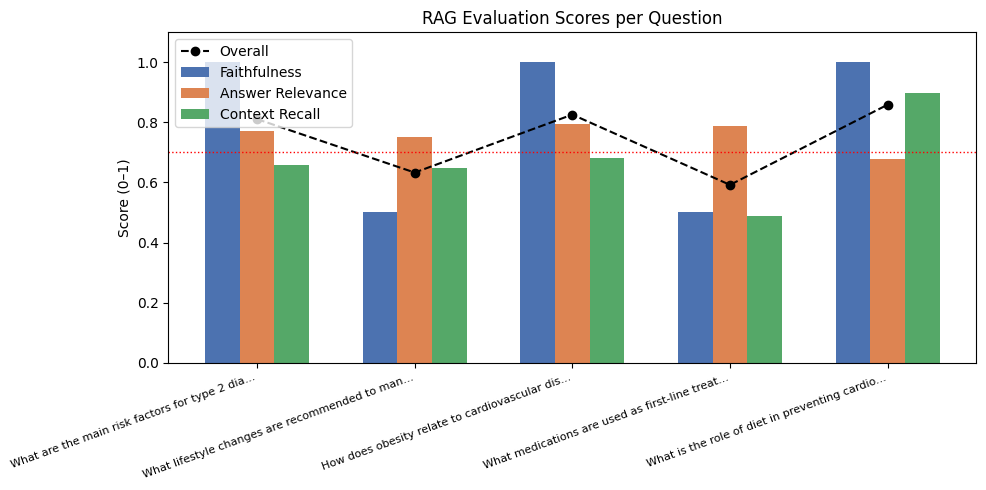

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.DataFrame(eval_results)
df['short_q'] = df['question'].str[:45] + '...'

# Summary table
print('=== Evaluation Summary ===')
summary = df[['faithfulness','answer_relevance','context_recall','overall']].describe().round(3)
print(summary)

# Bar chart
fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(df))
width = 0.22
ax.bar([i - width for i in x], df['faithfulness'],     width, label='Faithfulness',     color='#4C72B0')
ax.bar([i          for i in x], df['answer_relevance'], width, label='Answer Relevance', color='#DD8452')
ax.bar([i + width for i in x], df['context_recall'],   width, label='Context Recall',   color='#55A868')
ax.plot(x, df['overall'], 'ko--', label='Overall', linewidth=1.5, markersize=6)

ax.set_xticks(list(x))
ax.set_xticklabels(df['short_q'], rotation=20, ha='right', fontsize=8)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score (0–1)')
ax.set_title('RAG Evaluation Scores per Question')
ax.legend()
ax.axhline(0.7, color='red', linestyle=':', linewidth=1, label='Acceptance threshold')
plt.tight_layout()
plt.show()

## 💡 Discussion Questions

1. **Chunk size matters.** Change `chunk_size` from 500 to 200 and re-run. Do scores improve or worsen? Why?
2. **Retrieval depth.** Change `k=3` to `k=6`. How does this affect faithfulness vs. answer relevance?
3. **What if the answer isn't in the documents?** Ask: *"What is the best diet for preventing Alzheimer's?"*
   Does the model stay grounded, or does it hallucinate?
4. **Embedding model quality.** Replace `all-MiniLM-L6-v2` with `BAAI/bge-small-en-v1.5`.
   Does retrieval quality change?
5. **Limitations of our evaluation.** Our metrics are heuristic. What could a human judge catch
   that cosine similarity cannot?

---

## 🗺 Where to go next

- **Advanced chunking**: Semantic chunking, parent-document retrieval
- **Re-ranking**: Use a cross-encoder to re-rank retrieved chunks before generation
- **Evaluation frameworks**: [RAGAS](https://github.com/explodinggradients/ragas), [TruLens](https://github.com/truera/trulens)
- **Production vector stores**: Pinecone, Weaviate, Chroma, Qdrant
- **Fine-tuning**: Domain-adapt the embedding model on medical text for better retrieval